# Practical process capability workflows

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FEI-JIANG/uccap/blob/main/examples/notebooks/01_workflow.ipynb)

Companion notebook to F. Jiang and L. Yang, *Practical process capability indices workflows*,
Int. J. Adv. Manuf. Technol. 143:3581–3599 (2026), [doi:10.1007/s00170-026-17782-7](https://doi.org/10.1007/s00170-026-17782-7)
([arXiv:2604.15544](https://arxiv.org/abs/2604.15544)).

The article describes how to go from raw measurements to capability indices that are valid for the
data at hand: check the data, test normality, choose the sigma, and switch to percentile indices
when the data are not normal. This notebook walks through that workflow with `uccap`
(module `uccap.workflow`) on simulated data, and ends by reproducing part of the article's case study.

In [1]:
# On Colab or another fresh environment, install uccap first
try:
    import uccap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "uccap[plot] @ git+https://github.com/FEI-JIANG/uccap"], check=True)

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import uccap
np.set_printoptions(precision=4, suppress=True)

## 1. A normal dimension

32 parts in production order, specification 4.62 ± 0.10. `capability_study` runs the whole
workflow: data checks, outlier screening, Anderson–Darling normality test, within and overall sigma,
and the indices.

In [3]:
x = np.random.default_rng(42).normal(loc=4.625, scale=0.023, size=32)
study = uccap.capability_study(x, lsl=4.52, usl=4.72, target=4.62)
print(study.report())

  PROCESS CAPABILITY STUDY
         Sample size : 32
       Specification : LSL = 4.52   Target = 4.62   USL = 4.72
                Mean : 4.6266
        Sigma within : 0.0200   (average moving range)
       Sigma overall : 0.0194   (within / overall = 1.03)
      Normality test : Anderson-Darling
             p-value : 0.920   (normal at alpha = 0.05)
         Other tests : SW p = 0.984   K2 p = 0.757   (reference)
            Skewness : -0.076   (excess kurtosis 0.163)
            Outliers : 2 flagged (obs. 5, 31), review before use
----------------------------------------------------------------
  Normal-based indices

              Within              Overall
                  Cp :  1.666          Pp :  1.716
                 Cpk :  1.556         Ppk :  1.603
                 Cpu :  1.556         Ppu :  1.603
                 Cpl :  1.776         Ppl :  1.830
                 Cpm :  1.582         Ppm :  1.625
                Cpmk :  1.477        Ppmk :  1.518
----------------------

The report gives both families of indices: **Cp, Cpk** use the within (short-term) sigma, estimated from
moving ranges because the parts were measured one at a time; **Pp, Ppk** use the overall sigma, the
ordinary standard deviation. Their ratio tells whether the process drifted during the run.

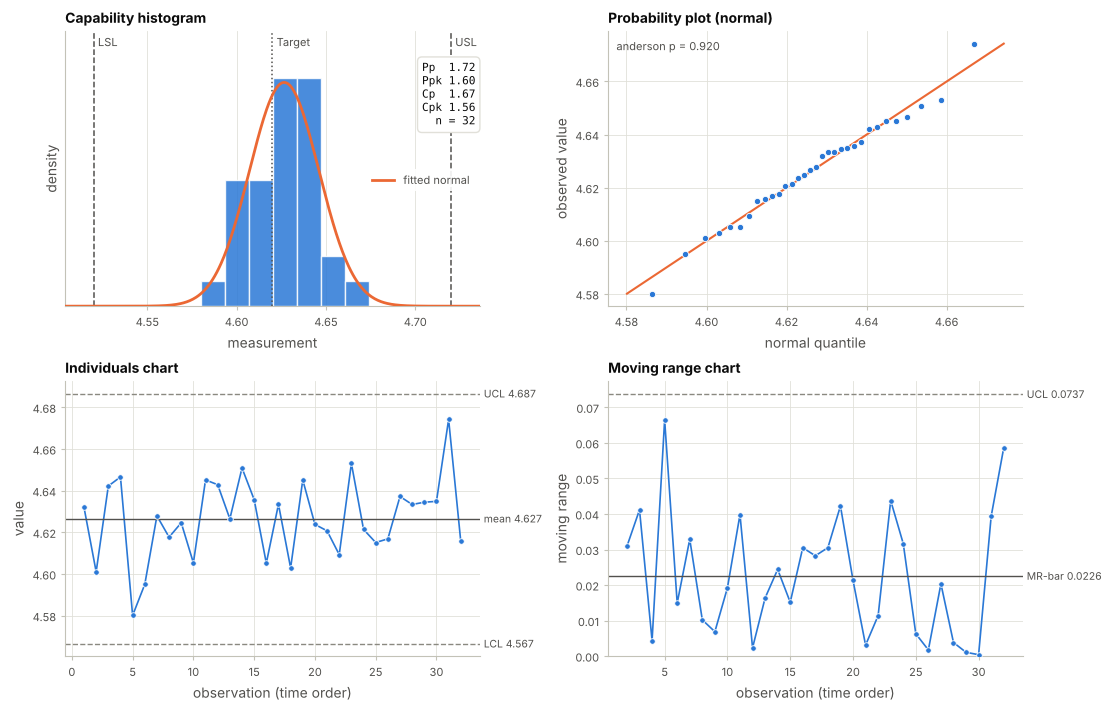

In [4]:
study.plot();

## 2. Within sigma: which estimator?

For individual measurements the article compares the average moving range (AMR), the median moving
range (MMR, robust to isolated spikes) and the root mean square of successive differences (SRMSSD).
With a single spike in the data the AMR estimate grows, the MMR estimate hardly moves.

In [5]:
from uccap.workflow.sigma import sigma_amr, sigma_mmr, sigma_srmssd, sigma_overall

spiked = x.copy()
spiked[15] += 0.12                        # one gross reading
for name, data in (("clean", x), ("one spike", spiked)):
    print(f"{name:>10}:  overall {sigma_overall(data):.4f}   AMR {sigma_amr(data):.4f}   "
          f"MMR {sigma_mmr(data):.4f}   SRMSSD {sigma_srmssd(data):.4f}")

     clean:  overall 0.0194   AMR 0.0200   MMR 0.0213   SRMSSD 0.0203
 one spike:  overall 0.0257   AMR 0.0235   MMR 0.0213   SRMSSD 0.0255


The outlier screen flags the spike (here together with one borderline reading); after a flagged point has been confirmed as a special cause (for example a
measurement error) the study can be rerun without it. The report lists what was excluded.

In [6]:
s = uccap.capability_study(spiked, lsl=4.52, usl=4.72, target=4.62)
print("flagged:", np.flatnonzero(s.outlier_mask))
print(s.without_outliers().report()[:900])

flagged: [15 30]


  PROCESS CAPABILITY STUDY
         Sample size : 30   (of 32; 2 excluded: obs. 16, 31)
       Specification : LSL = 4.52   Target = 4.62   USL = 4.72
                Mean : 4.6257
        Sigma within : 0.0178   (average moving range)
       Sigma overall : 0.0176   (within / overall = 1.02)
      Normality test : Anderson-Darling
             p-value : 0.588   (normal at alpha = 0.05)
         Other tests : SW p = 0.442   K2 p = 0.302   (reference)
            Skewness : -0.595   (excess kurtosis -0.079)
            Outliers : 2 flagged (obs. 16, 31), excluded
----------------------------------------------------------------
  Normal-based indices

              Within              Overall
                  Cp :  1.870          Pp :  1.898
                 Cp


## 3. Non-normal data: percentile indices

Flatness has an upper limit only and is naturally skewed. The normality test fails, so the workflow
fits candidate distributions, ranks them by AICc and computes the percentile indices
CNpk = (USL − P50) / (P99.865 − P50).

In [7]:
y = np.random.default_rng(7).lognormal(mean=np.log(0.02), sigma=0.5, size=60)
flat = uccap.capability_study(y, usl=0.12)
print(flat.report())

  PROCESS CAPABILITY STUDY
         Sample size : 60
       Specification : USL = 0.12   (one-sided)
                Mean : 0.0198
        Sigma within : 0.0090   (average moving range)
       Sigma overall : 0.0091   (within / overall = 0.98)
      Normality test : Anderson-Darling
             p-value : 0.002   (non-normal at alpha = 0.05)
         Other tests : SW p = 0.000   K2 p = 0.000   (reference)
            Skewness :  1.314   (excess kurtosis 2.379)
            Outliers : 4 flagged (obs. 8, 45, 50, 59), review before use
----------------------------------------------------------------
  Percentile-based indices (best fit: lognormal)

                CNpk :  2.056
                CNpu :  2.056
----------------------------------------------------------------
  Distribution ranking (sorted by AICc; lower is better)

        Distribution   k   AIC        BIC        AICc       dAICc
           lognormal : 2   -406.0     -401.8     -405.8     0.0
                 lev : 2   -405.5 

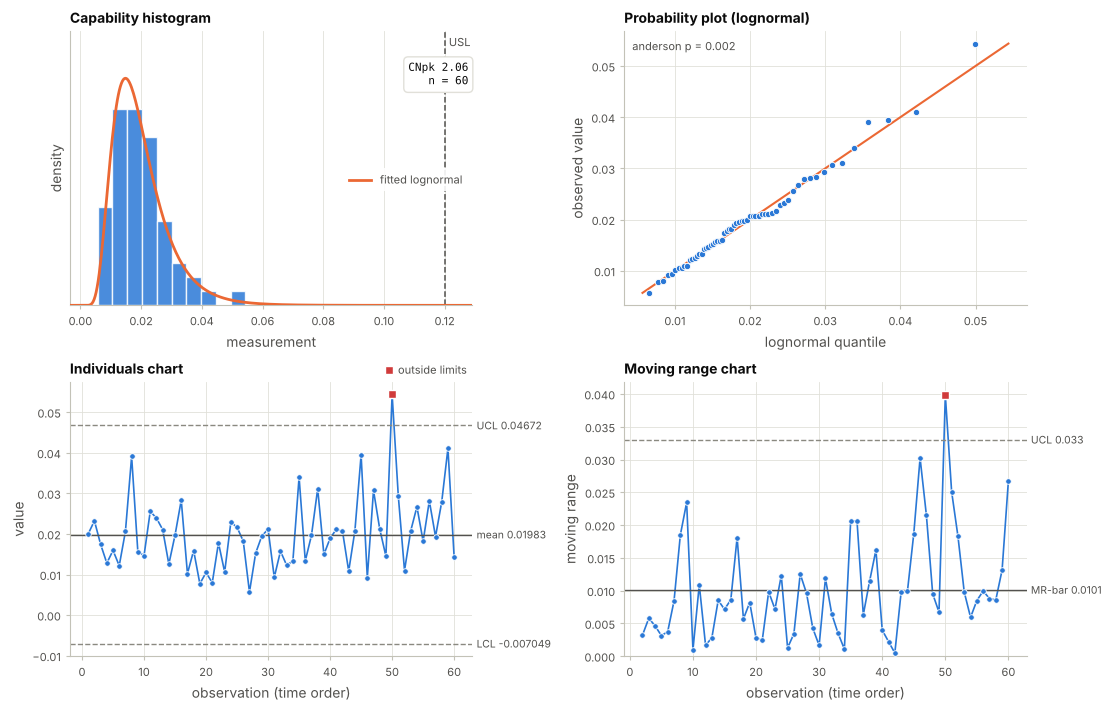

In [8]:
flat.plot();

Using normal-theory indices here would be misleading: compare the normal Ppu with the percentile
index used for approval.

In [9]:
from uccap.workflow import Spec
from uccap.workflow.indices import normal_indices
naive = normal_indices(y.mean(), y.std(ddof=1), y.std(ddof=1), Spec(usl=0.12))
print(f"normal-theory Ppu {naive['Cpu']:.3f}   percentile {flat.cpk_name} {flat.cpk:.3f}")

normal-theory Ppu 3.656   percentile CNpk 2.056


## 4. The article's case study

Section 6 of the article analyses nine dimensions of 32 parts. `validation/workflow_case_study.py`
recomputes dimension 105 (target 23.580 ± 0.100): the overall sigma, the 18 within-sigma estimates
(AMR and MMR, windows 2 to 10) and the indices of Tables 3–5, next to the printed values.

In [10]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "validation"))
import workflow_case_study
workflow_case_study.main()

Table 1: constants (article, uccap)
  w=2   d2 1.1284 1.1284   c4 0.7979 0.7979   d4 0.9539 0.9539
  w=3   d2 1.6926 1.6926   c4 0.8862 0.8862   d4 1.5878 1.5878
  w=4   d2 2.0588 2.0588   c4 0.9213 0.9213   d4 1.9783 1.9783
  w=5   d2 2.3259 2.3259   c4 0.9400 0.9400   d4 2.2569 2.2569
  w=6   d2 2.5344 2.5344   c4 0.9515 0.9515   d4 2.4717 2.4717
  w=7   d2 2.7044 2.7044   c4 0.9594 0.9594   d4 2.6455 2.6455
  w=8   d2 2.8472 2.8472   c4 0.9650 0.9650   d4 2.7908 2.7908
  w=9   d2 2.9700 2.9700   c4 0.9693 0.9693   d4 2.9154 2.9154
  w=10  d2 3.0775 3.0775   c4 0.9727 0.9727   d4 3.0242 3.0242

Tables 3-5, dimension 105 (article, uccap)
  estimator           sigma         Cp / Pp       Cpk / Ppk
  overall   0.0153 0.0153   2.172 2.172   1.368 1.368   0.02 %
  AMR2      0.0151 0.0151   2.201 2.213   1.386 1.394   0.57 %
  AMR3      0.0156 0.0156   2.130 2.137   1.342 1.346   0.33 %
  AMR4      0.0152 0.0152   2.186 2.187   1.377 1.378   0.06 %
  AMR5      0.0153 0.0153   2.172 2.175  

All sigma estimates and Pp, Ppk agree to the printed decimals; see `docs/validation.md` for the note
on the within-sigma Cp and Cpk.